# **Laboratório 1 - Comparação de Parâmetros**

In [ ]:
# Importação de bibliotecas

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
# Importação de módulos para criação do Dataset

from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split

In [ ]:
# Criação do Dataset

X,y = make_classification(n_samples=1000,
                         n_features=6,
                         n_informative=4,
                         n_redundant=2,
                         weights=[0.7, 0.3], # 70% x 30%
                         random_state=42
                         )

In [ ]:
# Desbalanceamento do Dataset

X[:,0] = X[:,0] * 10000
X[:,1] = X[:,1] * 50

In [ ]:
# Divisão de Treino e Teste

X_treino, X_teste, y_treino, y_teste = train_test_split(X,
                                                        y,
                                                        test_size=0.2,
                                                        random_state=42,
                                                        stratify=y)

In [ ]:
# Importações de módulos para criação do Pipeline

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier

In [ ]:
# Geração do Pipeline

esteira = Pipeline([
    ('escalonador',StandardScaler()),
    ('rede_neural',MLPClassifier(max_iter=1000, random_state=42))
    ])

In [ ]:
# Parametrização do GridSearch

grade_parametros = {
    'rede_neural__hidden_layer_sizes':[(8,4),(16,8)],
    'rede_neural__activation':['relu','tanh'],
    'rede_neural__learning_rate_init':[0.001,0.01]
}

In [ ]:
# Implementação do GridSearch

from sklearn.model_selection import GridSearchCV

In [ ]:
# Criação do Grid

otimizador = GridSearchCV(estimator=esteira,
                          param_grid=grade_parametros,
                          cv=5,
                          scoring='f1',
                          n_jobs=-1,
                          verbose=1
                          )

In [24]:
# Fit no Otimizador

otimizador.fit(X_treino,y_treino)

Fitting 5 folds for each of 8 candidates, totalling 40 fits


GridSearchCV(cv=5,
             estimator=Pipeline(steps=[('escalonador', StandardScaler()),
                                       ('rede_neural',
                                        MLPClassifier(max_iter=1000,
                                                      random_state=42))]),
             n_jobs=-1,
             param_grid={'rede_neural__activation': ['relu', 'tanh'],
                         'rede_neural__hidden_layer_sizes': [(8, 4), (16, 8)],
                         'rede_neural__learning_rate_init': [0.001, 0.01]},
             scoring='f1', verbose=1)

In [26]:
# Exibindo melhor F1 Score

print(f"Melhor F1 Score encontrado na validação: {otimizador.best_score_:.4f}")

Melhor F1 Score encontrado na validação: 0.8934


In [30]:
# Exibindo melhores parâmetros

print(f"Melhores parâmetros encontrados na validação: {otimizador.best_params_}")

Melhores parâmetros encontrados na validação: {'rede_neural__activation': 'tanh', 'rede_neural__hidden_layer_sizes': (8, 4), 'rede_neural__learning_rate_init': 0.01}


In [ ]:
# Predição do Otimizador

y_pred = otimizador.predict(X_teste)

In [50]:
# Importando o Classification Report e plotando os resultados

from sklearn.metrics import classification_report

print("                  \033[1mResultado Final do Modelo\033[0m")
print(classification_report(y_teste,y_pred, target_names=["Bom Pagador", "Inadimplente"]))

                  Resultado Final do Modelo
              precision    recall  f1-score   support

 Bom Pagador       0.92      0.94      0.93       139
Inadimplente       0.86      0.82      0.84        61

    accuracy                           0.91       200
   macro avg       0.89      0.88      0.89       200
weighted avg       0.90      0.91      0.90       200



In [ ]:
# Importação do módulo da matriz de confusão

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

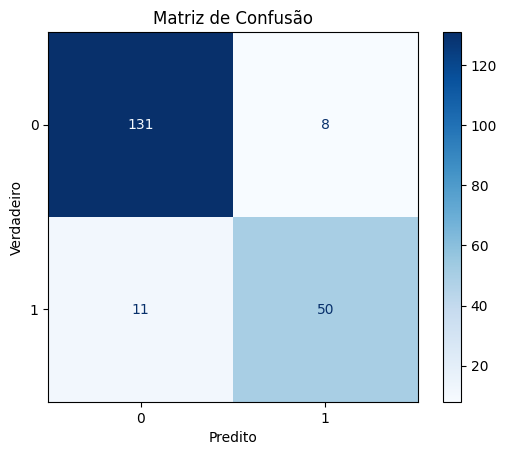

In [52]:
# Plotando a Matriz de Confusão

ConfusionMatrixDisplay.from_predictions(y_teste,y_pred,
                                        cmap=plt.cm.Blues,
                                        )
plt.title("Matriz de Confusão")
plt.xlabel("Predito")
plt.ylabel("Verdadeiro")
plt.show()

# **Laboratório 2 - Comparação de Modelos**

In [ ]:
# Importações de outros algoritmos

from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier

# from sklearn.neighbors import KNeighborsClassifier
# from sklearn.svm import SVC

In [ ]:
# Criação do "torneio" de modelos (Pipelines)

modelos_torneio = {
    "01. Árvore de Decisão":Pipeline([
        ('scaler',StandardScaler()),
        ('clf',DecisionTreeClassifier(max_depth=5,
                                      random_state=42))
    ]),

    "02. Random Forest":Pipeline([
        ('scaler',StandardScaler()),
        ('clf',RandomForestClassifier(n_estimators=100,
                                      random_state=42))
    ]),

    "03. AdaBoost":Pipeline([
        ('scaler',StandardScaler()),
        ('clf',AdaBoostClassifier(n_estimators=100,
                                  random_state=42))
    ]),

    "04. Rede Neural":Pipeline([
        ('scaler',StandardScaler()),
        ('clf',MLPClassifier(hidden_layer_sizes=(8,4),
                             max_iter=1000,
                             random_state=42))
    ])
    }

In [ ]:
# Importação do Cross Validate e Cross Val Score

from sklearn.model_selection import cross_validate, cross_val_score

In [ ]:
# Importando módulo comparativo de tempo

import time
from datetime import datetime

In [85]:
# Criação do Cross Validation entre os modelos escolhidos

resultados = []
for nome, esteira_modelos in modelos_torneio.items():
    print(f"Iniciando treinamento do modelo: \033[1m{nome}\033[0m")

    # Marcação do tempo de início
    tempo_inicio = time.time()

    scores = cross_val_score(esteira_modelos,
                             X_treino,
                             y_treino,
                             cv=5,
                             scoring='f1',
                             n_jobs=-1)

    # Append dos Resultados

    resultados.append({
    'Modelo':nome,
    'F1-Score Médio':scores.mean(),
    'Desvio Padrão':scores.std(),
    'Tempo de Execução':tempo_execucao
})
    # Marcação do tempo de término
    tempo_fim = time.time()

    # Criação do cálculo de tempo
    tempo_execucao = time.time() - tempo_inicio

# Mensagem ao finalizar todos os modelos
print("\n\033[1;32mModelos treinados com sucesso!\033[0m")

Iniciando treinamento do modelo: 01. Árvore de Decisão
Iniciando treinamento do modelo: 02. Random Forest
Iniciando treinamento do modelo: 03. AdaBoost
Iniciando treinamento do modelo: 04. Rede Neural

Modelos treinados com sucesso!


In [86]:
# Criação da Tabela do Torneio

tabela_torneio = pd.DataFrame(resultados).sort_values(
    by='F1-Score Médio',
    ascending=False
)

display(tabela_torneio)

,Modelo,F1-Score Médio,Desvio Padrão,Tempo de Execução
3,04. Rede Neural,0.868660,0.022369,1.269958
1,02. Random Forest,0.864355,0.039004,0.063689
2,03. AdaBoost,0.815946,0.055293,1.168256
0,01. Árvore de Decisão,0.788698,0.063928,5.630877


In [87]:
# Insights dos Modelos

# Modelo com maior F1-Score
melhor_f1 = tabela_torneio.loc[
    tabela_torneio['F1-Score Médio'].idxmax()
]

# Modelo mais rápido
mais_rapido = tabela_torneio.loc[
    tabela_torneio['Tempo de Execução'].idxmin()
]

# Modelo mais consistente
mais_consistente = tabela_torneio.loc[
    tabela_torneio['Desvio Padrão'].idxmin()
]

# Cálculo do custo-benefício
# Quanto maior o F1 e menor o tempo, melhor
tabela_torneio['Custo-Benefício'] = (
    tabela_torneio['F1-Score Médio'] /
    tabela_torneio['Tempo de Execução']
)

melhor_custo_beneficio = tabela_torneio.loc[
    tabela_torneio['Custo-Benefício'].idxmax()
]


# Exibição dos Insights
print("\033[1mInsights do Torneio\033[0m")

print(
    f"\n\033[1mMelhor desempenho (F1-Score):\033[0m "
    f"{melhor_f1['Modelo']} "
    f"com F1-Score de {melhor_f1['F1-Score Médio']:.4f}"
)

print(
    f"\n\033[1mModelo mais rápido:\033[0m "
    f"{mais_rapido['Modelo']} "
    f"com {mais_rapido['Tempo de Execução']:.2f} segundos"
)

print(
    f"\n\033[1mModelo mais consistente:\033[0m "
    f"{mais_consistente['Modelo']} "
    f"com desvio padrão de {mais_consistente['Desvio Padrão']:.4f}"
)

print(
    f"\n\033[1mMelhor Custo-Benefício:\033[0m "
    f"{melhor_custo_beneficio['Modelo']} "
    f"(F1: {melhor_custo_beneficio['F1-Score Médio']:.4f} | "
    f"Tempo: {melhor_custo_beneficio['Tempo de Execução']:.2f}s)"
)

Insights do Torneio

Melhor desempenho (F1-Score): 04. Rede Neural com F1-Score de 0.8687

Modelo mais rápido: 02. Random Forest com 0.06 segundos

Modelo mais consistente: 04. Rede Neural com desvio padrão de 0.0224

Melhor Custo-Benefício: 02. Random Forest (F1: 0.8644 | Tempo: 0.06s)
